<a href="https://colab.research.google.com/github/Mukundan-T/seqADAGE/blob/main/Py/muk_uADAGE/BaselineEcoliModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline E. coli Models

### By: Mukundan Thanigaivelan

### September 22, 2026

In this notebook, we will be training baseline E. coli models with the standard ADAGE loss function (mean squared error) with **no regularizer** as control models.

## 0. Connect to GitHub

In [1]:
!git clone https://github.com/Mukundan-T/seqADAGE.git

Cloning into 'seqADAGE'...
remote: Enumerating objects: 950, done.
remote: Counting objects: 100% (172/172), done.
remote: Compressing objects: 100% (101/101), done.
remote: Total 950 (delta 133), reused 78 (delta 71), pack-reused 778 (from 2)
Receiving objects: 100% (950/950), 59.12 MiB | 25.61 MiB/s, done.
Resolving deltas: 100% (552/552), done.


In [2]:
%cd seqADAGE/Py/muk_transfer_learning

/content/seqADAGE/Py/muk_transfer_learning


In [3]:
!pip install -qq tensorflow keras statsmodels seaborn keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 7.4 MB/s eta 0:00:00


## 1. Loading classes & modules

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [6]:
# ADAGE
from adage import Adage as ad, SeqAdage, LinkedAE

# Data Analysis
import pandas as pd
import numpy as np
import keras

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Miscellaneous
import zipfile
import time
import json
import tensorflow as tf
from types import SimpleNamespace

In [7]:
# check CPU and GPU available in runtime
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(tf.test.is_built_with_cuda())

Num CPUs Available:  1
Num GPUs Available:  1
True


## 2. Unregularized E. coli ADAGE

Hyperparameter search results:

* Units: 70
* Dropout: 0
* Activation 1: TanH
* Activation 2: TanH
* Shuffle: True
* Initialization: glorot_uniform
* kl1: 0
* kl2: 0
* lr: 0.051000000000000004
* bs: 20
* mm: 0.7000000000000001

### 2a. Find and save optimal model hyperparameters

In [8]:
# Load filtered and re-normalized data
filename = '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv'

filtered_df = pd.read_csv(filename, index_col = 0)
filtered_df.shape

(3608, 10233)

In [9]:
# Find optimal hyperparameter values
model_trainer = SeqAdage.SeqAdage(filename)
best_hps, tuner = model_trainer.tune_model(
  seed = 42,
  k1 = [0, 0, 0.1],
  k2 = [0, 0, 0.1],
  d = [0, 0, 0.1]
)

Trial 90 Complete [00h 01m 10s]
val_loss: 0.011332492344081402

Best val_loss So Far: 0.007184627931565046
Total elapsed time: 00h 22m 44s
Results summary
Results in /content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk_42
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 0072 summary
Hyperparameters:
units: 70
dropout: 0.0
act1: tanh
shuffle: True
init: glorot_uniform
kl1: 0.0
kl2: 0.0
lr: 0.051000000000000004
bs: 20
mm: 0.7000000000000001
act2: tanh
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0068
Score: 0.007184627931565046

Trial 0050 summary
Hyperparameters:
units: 90
dropout: 0.0
act1: tanh
shuffle: True
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.081
bs: 20
mm: 0.4
act2: tanh
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0048
Score: 0.007558437995612621

Trial 0073 summary
Hyperparameters:
units: 10
dropout: 0.0
act1: celu
shuffle

In [10]:
# Optimal hyperparameters - decide based on higher value of units and batch size (bs)
best_hps[0].values

{'units': 70,
 'dropout': 0.0,
 'act1': 'tanh',
 'shuffle': True,
 'init': 'glorot_uniform',
 'kl1': 0.0,
 'kl2': 0.0,
 'lr': 0.051000000000000004,
 'bs': 20,
 'mm': 0.7000000000000001,
 'act2': 'tanh',
 'tuner/epochs': 50,
 'tuner/initial_epoch': 17,
 'tuner/bracket': 2,
 'tuner/round': 2,
 'tuner/trial_id': '0068'}

In [11]:
# Save optimal model hyperparameters
optimal_hps = {param: val for param, val in best_hps[0].values.items() if not param.startswith('tuner')}
with open('/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_control_model_hps.json', "w") as f:
  json.dump(optimal_hps, f)

### 2b. Train, choose, and save optimal models

In [12]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_control_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

# Train models
control_models = {}
ec_objs = []
seeds = list(range(75))

for seed in seeds:
  sa = SeqAdage.SeqAdage(
    filename,
    seed = seed + 100,
    enc_dim = optimal_hps['units'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    act = optimal_hps['act1'],
    act2 = optimal_hps['act2'],
    epochs = 50,
    init = optimal_hps['init'],
    batch_size = optimal_hps['bs'],
    dropout = optimal_hps['dropout'],
    mm = optimal_hps['mm'],
    lr = optimal_hps['lr']
  )
  sa.train_model()
  temp = ad.Adage(sa.autoencoder, sa.history, sa.all_comp)

  ec_objs.append(sa)
  control_models[seed] = temp

Streaming output truncated to the last 5000 lines.
Epoch 26/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0180 - val_loss: 0.0182
Epoch 27/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0179 - val_loss: 0.0181
Epoch 28/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0179 - val_loss: 0.0180
Epoch 29/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0178 - val_loss: 0.0180
Epoch 30/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0177 - val_loss: 0.0179
Epoch 31/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0176 - val_loss: 0.0179
Epoch 32/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0176 - val_loss: 0.0178
Epoch 33/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0175 - val_loss: 0.0178
Epoch 34/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0174 - val_loss: 0.0177
Epoch 35/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0174 - val_loss: 0.0176
Epoch 36/50
461/461 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0173 - val_loss:

In [14]:
# Create enrichment dataframes
kegg_dfs = {}

for seed in control_models.keys():
  ec_kegg_ps = control_models[seed].set_kegg(
    '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ec_kegg_pathways.txt'
  )
  kegg_dfs[seed] = ec_kegg_ps

In [15]:
# Save sum of p-values and pathways to lists
p_val_sums = []
path_info = []

for df in kegg_dfs.values():
  p_val_sums.append(df.sum().sum())
  path_info.append(df.columns[(df > 1.5).any()].tolist())

In [16]:
# Inspect p-values
p_val_sums

[np.float64(414.3761217889502),
 np.float64(307.7274332853432),
 np.float64(401.1154169753875),
 np.float64(418.229855825557),
 np.float64(564.1675228587776),
 np.float64(763.0631144199322),
 np.float64(531.3822025672898),
 np.float64(668.2471127371101),
 np.float64(423.0617059515411),
 np.float64(576.8154791081602),
 np.float64(641.3098173943145),
 np.float64(562.1195203708418),
 np.float64(574.7487573654644),
 np.float64(651.7849118146576),
 np.float64(462.3789572446268),
 np.float64(499.9820338035349),
 np.float64(588.0002580893523),
 np.float64(584.7786122545024),
 np.float64(490.5473481769173),
 np.float64(562.2344633455624),
 np.float64(522.2989561834924),
 np.float64(554.7980399982803),
 np.float64(347.2648621599851),
 np.float64(399.39924145861573),
 np.float64(574.0106793206844),
 np.float64(428.5548732957083),
 np.float64(396.16159846261246),
 np.float64(459.3802837603652),
 np.float64(544.7383235034108),
 np.float64(754.3711741758506),
 np.float64(446.24420545548367),
 np.fl

In [17]:
# Save all 75 models
for seed in seeds:
  ec_objs[seed].autoencoder.save(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_best_model{seed+1}.keras'
  )

In [18]:
# Save KEGG enrichment matrices for the 2 best models
for seed in seeds:
  kegg_dfs[seed].to_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/kegg_dfs/ec_kegg_ps{seed+1}.csv',
  )

### 2c. Load optimal models

In [ ]:
model_filenames = [
  f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_best_model{i+1}.keras'
  for i in range(2)
]

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/Data/ec_control_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

In [ ]:
loaded_models = []

for file in model_filenames:
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    encoding_dim = optimal_hps['units'],
    act2 = optimal_hps['act2'],
    d = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init']
  )
  ae(tf.zeros((1, filtered_df.shape[0])))

  # Pull model weights
  with zipfile.ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Create ADAGE object
  adage = ad.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': [],
        'val_loss': [],
      }
    ),
    train_comp = pd.read_csv(
      '/content/drive/My Drive/Comp-Bio-Projs-S26/data/muk-in-use/ecmg_lcn01_medmean_normal_muk.csv',
      index_col = 0
    ),
  )

  # Add model to list
  loaded_models.append(adage)

### 2d. Loss curves and weight distributions

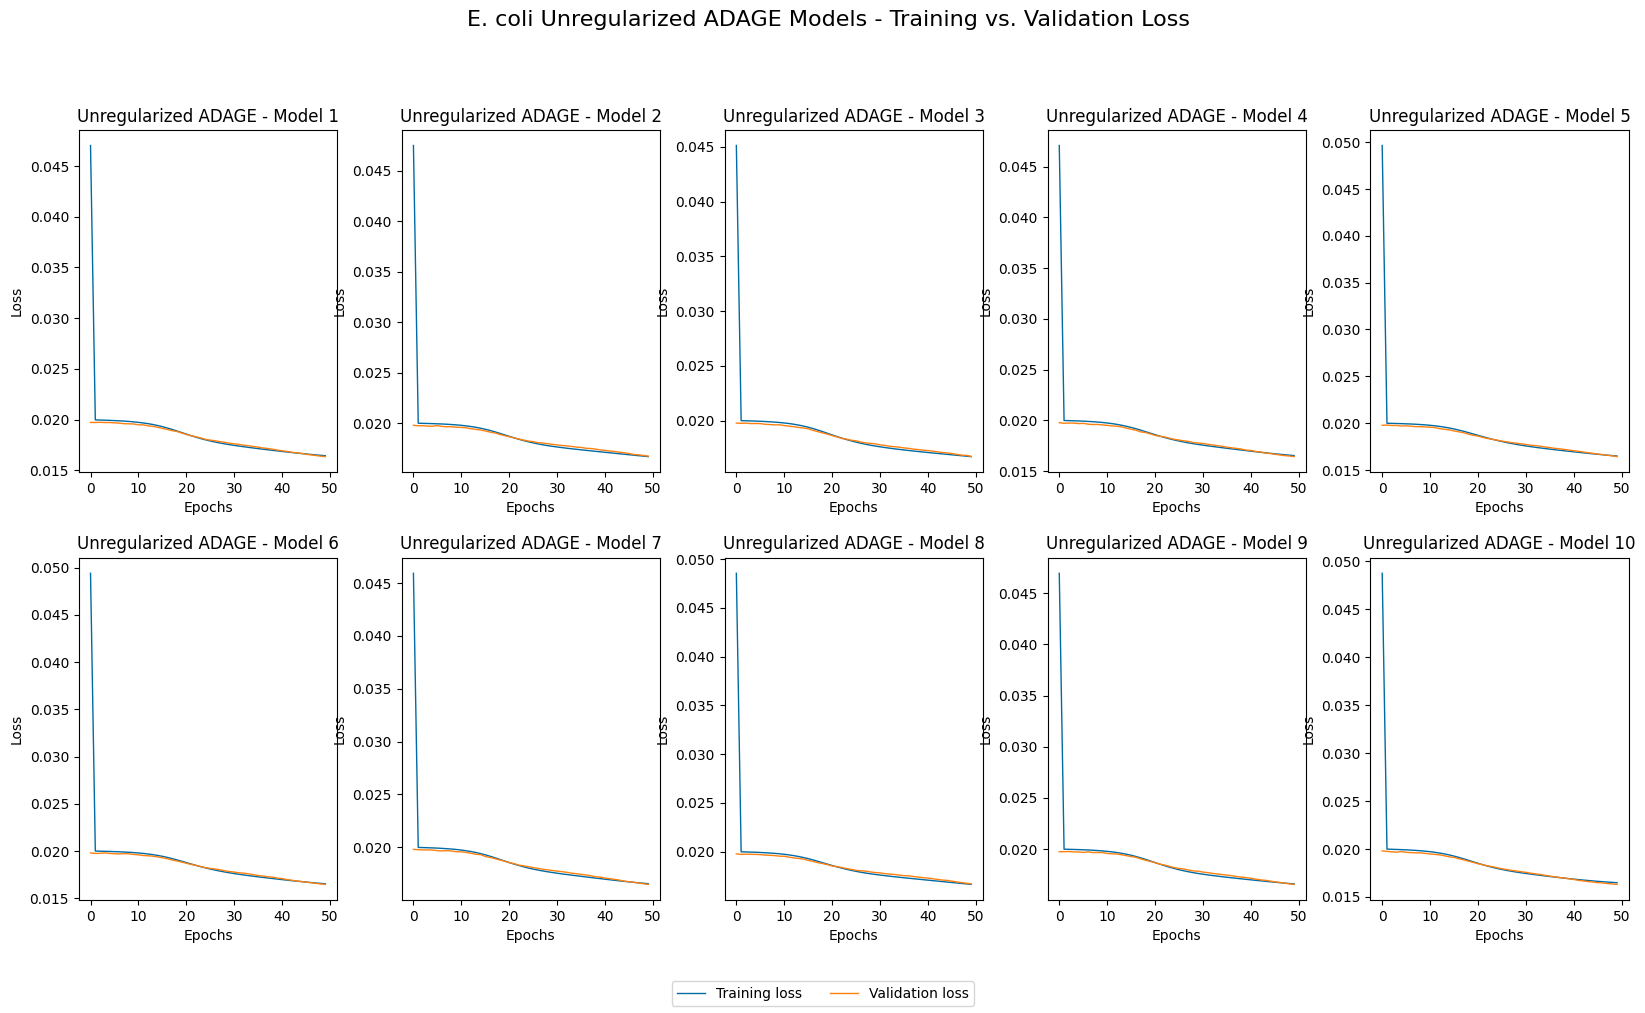

In [28]:
plot_titles = [
  f'Unregularized ADAGE - Model {i+1}'
  for i in range(10)
]
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli Unregularized ADAGE Models - Training vs. Validation Loss',
  fontsize = 16,
  y = 1
)

for i in range(2):
  for j in range(5):
    ax[i, j].plot(
      range(50),
      control_models[5*i + j].loss,
      linewidth = 1,
      label = 'Training loss'
    )
    ax[i, j].plot(
      range(50),
      control_models[5*i + j].val_loss,
      linewidth = 1,
      label = 'Validation loss'
    )
    ax[i, j].set(
      title = plot_titles[5*i + j],
      xlabel = 'Epochs',
      ylabel = 'Loss'
    )

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(
  handles,
  labels,
  loc = 'lower center',
  ncol = 2,
  fontsize = 10
)

fig.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_loss.png',
  dpi = 300,
  bbox_inches = 'tight'
)

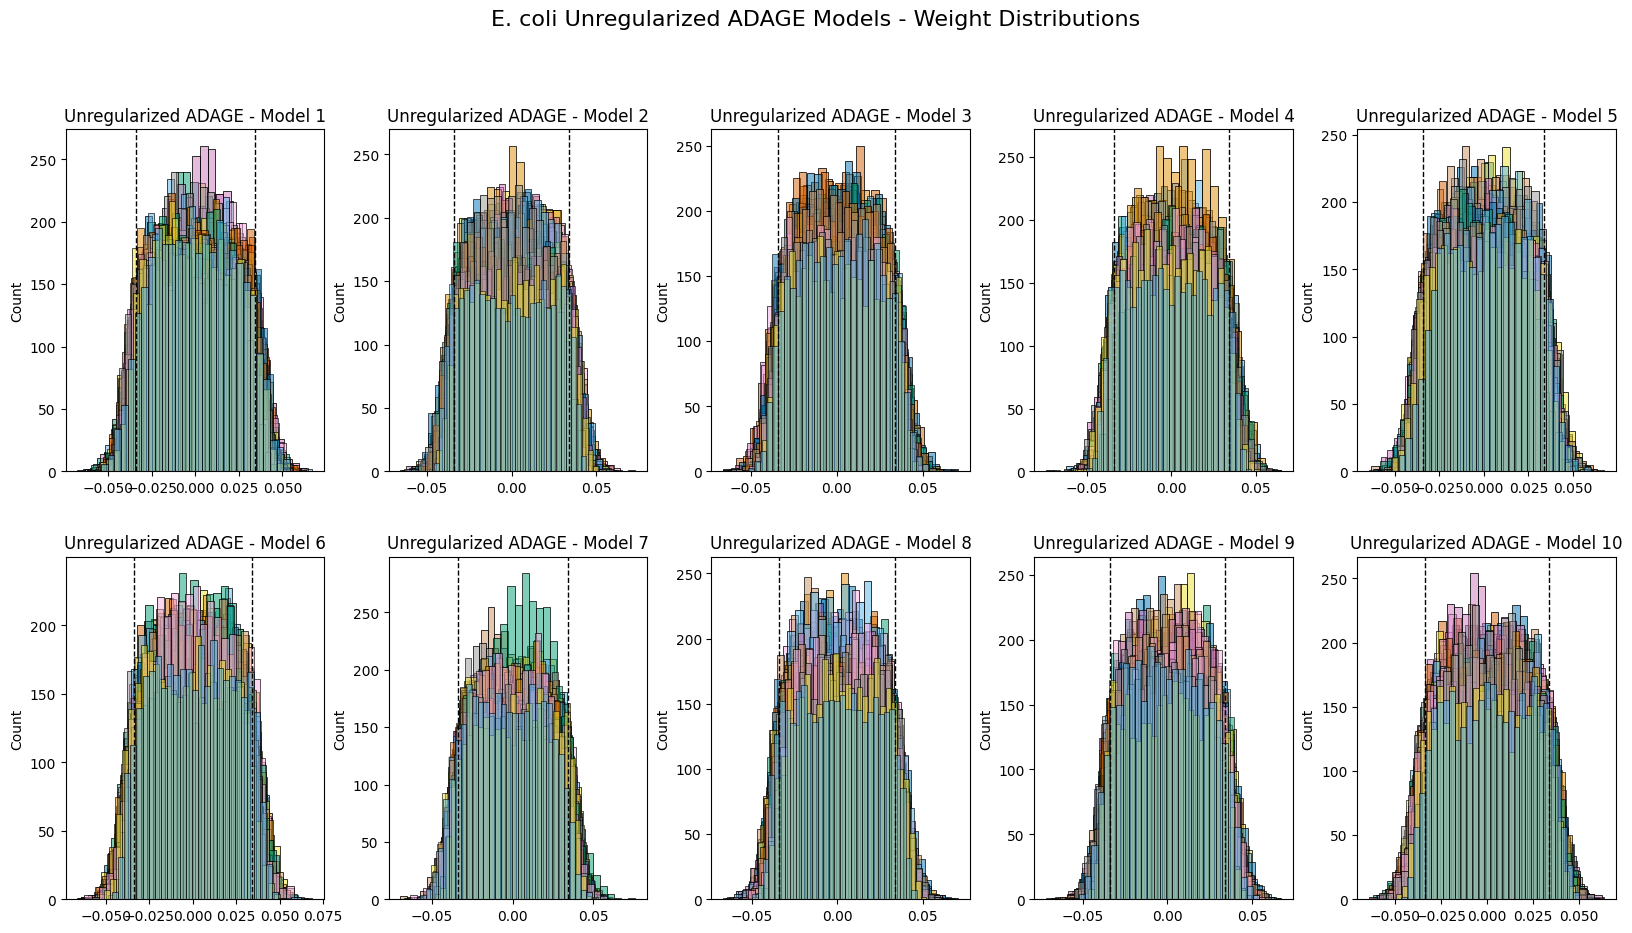

In [29]:
plot_titles = [
  f'Unregularized ADAGE - Model {i+1}'
  for i in range(10)
]

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli Unregularized ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(5):
    for node in range(optimal_hps['units']):
      weights = np.asarray(control_models[5*i + j].weights.T[node])
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays
      if len(weights) == 0:
        continue

      # Skip constant distributions
      if np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        bins = 30,
        color = colorblind_colors[node % len(colorblind_colors)],
        kde = False,
        alpha = 0.5
      )

    all_weights = np.asarray(control_models[5*i + j].weights.T).flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 1.5

    ax[i, j].axvline(
        x = cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].axvline(
        x = -cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].set(title = plot_titles[5*i + j])

fig.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_weight_dists.png',
  dpi = 300,
  bbox_inches = 'tight'
)

### 2e. Perform KEGG analysis

In [30]:
# Load KEGG p-value matrices
kegg_ps = [
  pd.read_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/kegg_dfs/ec_kegg_ps{i+1}.csv'
  )
  for i in range(75)
]

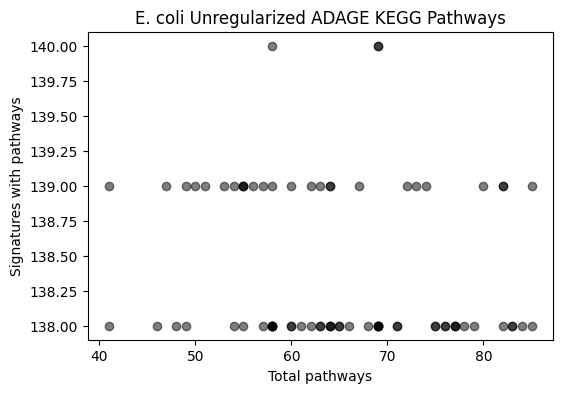

In [32]:
# Plot KEGG pathways
plt.figure(figsize = (6, 4))

for kegg_vals in kegg_ps:
  x = ((kegg_vals > 1.5).sum(0) > 0).sum()
  y = ((kegg_vals > 1.5).sum(1) > 0).sum()
  plt.scatter(x, y, alpha = 0.5, color = "black")

plt.title('E. coli Unregularized ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

plt.savefig(
  '/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/Plots/ec_control_kegg.png',
  dpi = 300,
  bbox_inches = 'tight'
)